# 03 · Reconstruction as an inverse problem: SVD and TSVD

Reconstruction inverts the response matrix, and the singular value decomposition $A = U\Sigma V^T$ shows what that inversion does. Each singular value $\sigma_i$ is how strongly the sensor sees one combination of modes; inverting it multiplies measurement noise by $1/\sigma_i$. Truncated SVD (TSVD) simply drops the combinations whose $\sigma_i$ falls below a fraction `rcond` of the largest.

The test case is deliberately hard: 152 Zernike modes (radial order 16) from only 80 sub-apertures, with noisy slopes.

**Check against theory:** for white slope noise of standard deviation $\sigma_s$, the reconstructed coefficients carry a noise variance of exactly $\sigma_s^2 \sum_{\text{kept}} 1/\sigma_i^2$.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIGURES = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from phase_screen import fourier_phase_screen
from psf_tools import strehl_ratio
from reconstruction import build_response_matrix, measure_slopes, rms, subaperture_masks
from zernike import generate_zernike_modes, make_pupil_grid

## 1. The singular spectrum

152 modes, 160 slopes, condition number 8.9e+15
Tip/tilt live mostly in singular direction #121 with sigma/sigma_max = 0.060


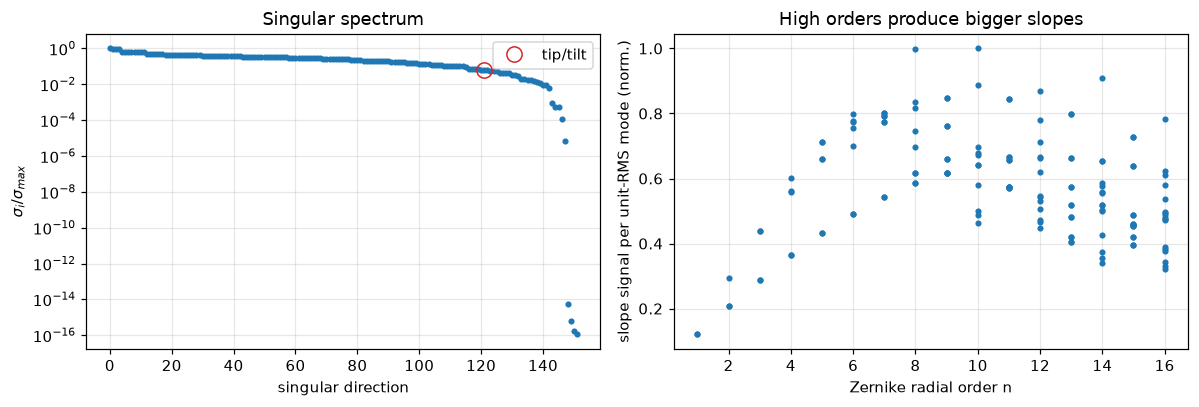

In [2]:
D, N, N_LENSLETS, MIN_FILL, MAX_ORDER = 1.0, 128, 10, 0.5, 16

X, Y, rho, theta, pupil, dx = make_pupil_grid(N=N, diameter=D)
modes = generate_zernike_modes(rho, theta, pupil, max_radial_order=MAX_ORDER)
A, names, _ = build_response_matrix(modes, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
U, S, Vt = np.linalg.svd(A, full_matrices=False)
centers, masks = subaperture_masks(X, Y, pupil, n_lenslets=N_LENSLETS, min_fill=MIN_FILL)
basis = np.column_stack([modes[name][pupil] for name in names])

tilt_columns = [names.index("Z1_+1"), names.index("Z1_-1")]
tilt_direction = int(np.argmax(np.sum(Vt[:, tilt_columns] ** 2, axis=1)))
print(f"{len(names)} modes, {A.shape[0]} slopes, condition number {S[0] / S[-1]:.1e}")
print(f"Tip/tilt live mostly in singular direction #{tilt_direction} with sigma/sigma_max = {S[tilt_direction] / S[0]:.3f}")

radial_order = np.array([int(name[1:].split("_")[0]) for name in names])
column_norm = np.linalg.norm(A, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(S / S[0], ".")
axes[0].semilogy(tilt_direction, S[tilt_direction] / S[0], "o", mfc="none", ms=10, color="C3", label="tip/tilt")
axes[0].set(xlabel="singular direction", ylabel=r"$\sigma_i / \sigma_{max}$", title="Singular spectrum")
axes[0].legend()
axes[1].plot(radial_order, column_norm / column_norm.max(), ".")
axes[1].set(xlabel="Zernike radial order n", ylabel="slope signal per unit-RMS mode (norm.)", title="High orders produce bigger slopes")
plt.tight_layout()
plt.show()

The right panel explains a trap. A unit-RMS Zernike mode of radial order $n$ has slopes roughly proportional to $n$, so tip and tilt produce the *weakest* signal in this basis. A cutoff above their singular value (about 0.06 here) silently removes them, even though tip/tilt carries most of the turbulent variance. Real systems avoid this with a separate tip/tilt loop, or by normalising the modes before truncation.

## 2. Check: noise propagation

With $\hat{\mathbf{a}} = V \Sigma^{+}_{\mathrm{TSVD}} U^T \mathbf{s}$ and white slope noise, the coefficient noise covariance is $\sigma_s^2 V \Sigma^{-2} V^T$ over the kept directions, so its trace is $\sigma_s^2 \sum_{\text{kept}} 1/\sigma_i^2$. Below, that prediction is compared with 2000 simulated noise draws.

In [3]:
SLOPE_NOISE = 0.1      # rad/m
RCONDS = np.array([1e-8, 1e-5, 1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 5e-2, 8e-2, 1e-1, 2e-1, 5e-1])


def tsvd_matrix(rcond):
    keep = S >= rcond * S[0]
    return (Vt[keep].T / S[keep]) @ U[:, keep].T, int(keep.sum())


rng = np.random.default_rng(1)
noise = rng.normal(scale=SLOPE_NOISE, size=(2000, A.shape[0]))
print("  rcond   kept   predicted noise var   simulated   [rad^2 summed over coefficients]")
for rcond in RCONDS[[0, 2, 3, 5, 7]]:
    R, kept = tsvd_matrix(rcond)
    predicted = SLOPE_NOISE**2 * np.sum(1.0 / S[:kept] ** 2)
    simulated = np.mean(np.sum((noise @ R.T) ** 2, axis=1))
    print(f"{rcond:7.0e} {kept:6d} {predicted:21.4g} {simulated:12.4g}")

  rcond   kept   predicted noise var   simulated   [rad^2 summed over coefficients]
  1e-08    148                 796.4          762
  1e-04    147                 3.165         3.09
  1e-03    143              0.003143     0.003099
  1e-02    140              0.001493     0.001487
  5e-02    126             0.0001838    0.0001836


## 3. TSVD on a noisy atmospheric measurement

Now a 1 rad RMS von Kármán screen is measured with the same slope noise and reconstructed at each cutoff. The residual is shown in total and with tip/tilt removed, together with the peak Strehl ratio.

Input: 1.00 rad RMS, 0.43 rad after tip/tilt removal
  rcond   kept   residual   tilt-removed   Strehl
  1e-08    148     44.181         44.180    0.003
  1e-05    147      7.211          7.209    0.058
  1e-04    147      7.211          7.209    0.058
  1e-03    143      0.266          0.266    0.934
  3e-03    143      0.266          0.266    0.934
  1e-02    140      0.201          0.200    0.961
  3e-02    133      0.262          0.254    0.937
  5e-02    126      0.258          0.250    0.939
  8e-02    116      0.924          0.219    0.928
  1e-01    115      0.924          0.219    0.928
  2e-01     87      0.986          0.395    0.830
  5e-01     12      1.000          0.427    0.808

Minimum residual at rcond = 1e-02: 0.201 rad with 140 of 152 directions kept


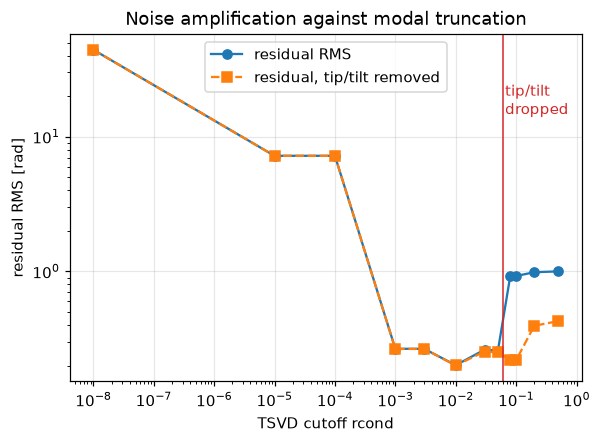

In [4]:
sheet, *_ = fourier_phase_screen(N=N, delta=dx, r0=0.2, L0=25.0, diameter=None, seed=3)
screen = np.where(pupil, sheet - np.mean(sheet[pupil]), np.nan)
screen *= 1.0 / rms(screen, pupil)                       # controlled 1 rad RMS input


def without_tilt(values):
    plane = np.column_stack([np.ones(pupil.sum()), X[pupil], Y[pupil]])
    return values - plane @ np.linalg.lstsq(plane, values, rcond=None)[0]


rows = []
for seed in range(5):
    _, slopes = measure_slopes(screen, pupil, X, Y, noise_std=SLOPE_NOISE, seed=seed, centers=centers, masks=masks)
    for rcond in RCONDS:
        R, kept = tsvd_matrix(rcond)
        residual = screen[pupil] - basis @ (R @ slopes.reshape(-1))
        residual -= residual.mean()
        residual_map = np.full(screen.shape, np.nan)
        residual_map[pupil] = residual
        rows.append((rcond, kept, np.std(residual), np.std(without_tilt(residual)), strehl_ratio(residual_map, pupil)))

rows = np.array(rows).reshape(5, len(RCONDS), 5).mean(axis=0)
best = int(np.argmin(rows[:, 2]))
print(f"Input: {rms(screen, pupil):.2f} rad RMS, {np.std(without_tilt(screen[pupil])):.2f} rad after tip/tilt removal")
print("  rcond   kept   residual   tilt-removed   Strehl")
for rcond, kept, total, high, strehl in rows:
    print(f"{rcond:7.0e} {kept:6.0f} {total:10.3f} {high:14.3f} {strehl:8.3f}")
print(f"\nMinimum residual at rcond = {RCONDS[best]:.0e}: {rows[best, 2]:.3f} rad with {rows[best, 1]:.0f} of {len(names)} directions kept")

fig, ax = plt.subplots(figsize=(6, 4.1))
ax.loglog(RCONDS, rows[:, 2], "o-", label="residual RMS")
ax.loglog(RCONDS, rows[:, 3], "s--", label="residual, tip/tilt removed")
ax.axvline(S[tilt_direction] / S[0], color="C3", lw=1)
ax.text(S[tilt_direction] / S[0] * 1.1, rows[:, 2].max() / 3, "tip/tilt\ndropped", color="C3")
ax.set(xlabel="TSVD cutoff rcond", ylabel="residual RMS [rad]", title="Noise amplification against modal truncation")
ax.legend(loc="upper center")
fig.savefig(FIGURES / "03_tsvd_scan.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

- With 152 modes and 80 sub-apertures the response matrix is singular to machine precision (condition number about $10^{16}$): some combinations of high-order modes are invisible to the sensor.
- The predicted noise variance $\sigma_s^2 \sum 1/\sigma_i^2$ matches 2000 simulated noise draws to within 4% at every cutoff, from about 800 rad² when everything is kept to $2\times10^{-4}$ rad² at rcond = 0.05.
- For the noisy 1 rad screen the residual is smallest at rcond = 0.01: 0.20 rad with 140 of 152 directions kept and Strehl 0.96. Smaller cutoffs amplify noise; larger ones underfit.
- Above rcond ≈ 0.06 tip and tilt are dropped: the residual jumps to 0.92 rad while peak Strehl stays at 0.93, because peak Strehl ignores image motion. Choose the cutoff by residual RMS, not by peak Strehl.